# Mobile Price Intelligence & Cross-Platform Competitive Analysis

## Exploratory Data Analysis (EDA)

### Business Objective

Analyze comparable mobile products across Amazon and Flipkart to understand:

- Which platform is more price-competitive?
- Where are the largest pricing gaps?
- Which brands show the greatest pricing variation?
- Do higher discounts translate into lower selling prices?
- Does lower pricing come with lower customer ratings?
- Which platform has stronger customer engagement based on review volume?
- Where are the biggest competitive pricing opportunities?

### Analysis Scope

This analysis uses mobile products collected from Amazon and Flipkart on **7 October 2026**.

Only **exactly matched product configurations** are included in the cross-platform comparison. Products with different RAM/ROM configurations across platforms are excluded to avoid misleading comparisons.

### Analytical Approach

The EDA focuses on:

1. Price competitiveness
2. Price gap magnitude
3. Brand-level pricing variation
4. Discount effectiveness
5. Price vs. customer rating
6. Customer review volume
7. Competitive opportunities

> **Note:** The dataset represents a single-day marketplace snapshot. Prices, discounts, ratings, review counts, and availability can change over time.

## Load the Final Comparison Dataset

The final comparison dataset contains only products that were successfully matched across Amazon and Flipkart using standardized product information and RAM/ROM configuration.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

df = pd.read_csv("../data/processed/final_mobile_price_comparison.csv")

print("Rows:", len(df))
print("Columns:", len(df.columns))

df.head()

Rows: 16
Columns: 27


,match_key,product_name,brand,ram_gb,rom_gb,amazon_price,amazon_mrp,amazon_discount_pct,amazon_rating,amazon_review_count,amazon_availability,amazon_product_url,amazon_scrape_at,flipkart_price,flipkart_mrp,flipkart_discount_pct,flipkart_rating,flipkart_review_count,flipkart_availability,flipkart_product_url,flipkart_scrape_at,price_difference,absolute_price_difference,cheaper_platform,discount_difference,rating_difference,review_difference
0,apple|apple iphone 16|128,Apple iPhone 16,Apple,NaN,128,86900,89900.0,3.34,4.5,2757.0,In Stock,https://www.amazon.in/iPhone-16-128-GB-Control...,07-10-2026 23:50,69900,NaN,NaN,4.6,199708,In Stock,https://www.flipkart.com/apple-iphone-16-white...,07-10-2026 23:49,17000,17000,Flipkart,NaN,-0.1,-196951.0
1,apple|apple iphone 17 pro|512,Apple iPhone 17 Pro,Apple,NaN,512,154900,NaN,NaN,4.5,646.0,In Stock,https://www.amazon.in/iPhone-Pro-512-Promotion...,07-10-2026 23:50,154900,NaN,NaN,4.7,5581,In Stock,https://www.flipkart.com/apple-iphone-17-pro-s...,07-10-2026 23:49,0,0,Same Price,NaN,-0.2,-4935.0
2,apple|apple iphone 17 pro max|256,Apple iPhone 17 Pro Max,Apple,NaN,256,142490,149900.0,4.94,4.7,663.0,In Stock,https://www.amazon.in/iPhone-Pro-Max-256-Promo...,07-10-2026 23:50,149900,NaN,NaN,4.7,2485,In Stock,https://www.flipkart.com/apple-iphone-17-pro-m...,07-10-2026 23:49,-7410,7410,Amazon,NaN,0.0,-1822.0
3,apple|apple iphone 17e|256,Apple iPhone 17e,Apple,NaN,256,79900,NaN,NaN,4.4,172.0,In Stock,https://www.amazon.in/Apple-iPhone-17e-256-GB/...,07-10-2026 23:50,64900,NaN,NaN,4.5,525,Unavailable,https://www.flipkart.com/apple-iphone-17e-whit...,07-10-2026 23:49,15000,15000,Flipkart,NaN,-0.1,-353.0
4,oneplus|oneplus nord 6|8.0|256,OnePlus Nord 6,OnePlus,8.0,256,47368,52999.0,10.62,4.4,2491.0,In Stock,https://www.amazon.in/OnePlus-Snapdragon-Segme...,07-10-2026 23:51,46178,52999.0,12.87,4.5,2624,In Stock,https://www.flipkart.com/oneplus-nord-6-fresh-...,07-10-2026 23:50,1190,1190,Flipkart,-2.25,-0.1,-133.0


## Data Overview

Before performing business analysis, verify the size, structure, data types, and missing values in the final comparison dataset.

In [2]:
print("========== DATASET OVERVIEW ==========")

print("Number of comparable products:", len(df))
print("Number of columns:", len(df.columns))

print("\n========== DATA TYPES ==========")
print(df.dtypes)

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

========== DATASET OVERVIEW ==========
Number of comparable products: 16
Number of columns: 27

========== DATA TYPES ==========
match_key                     object
product_name                  object
brand                         object
ram_gb                       float64
rom_gb                         int64
amazon_price                   int64
amazon_mrp                   float64
amazon_discount_pct          float64
amazon_rating                float64
amazon_review_count          float64
amazon_availability           object
amazon_product_url            object
amazon_scrape_at              object
flipkart_price                 int64
flipkart_mrp                 float64
flipkart_discount_pct        float64
flipkart_rating              float64
flipkart_review_count          int64
flipkart_availability         object
flipkart_product_url          object
flipkart_scrape_at            object
price_difference               int64
absolute_price_difference      int64
cheaper_platform    

In [3]:
df.describe()

,ram_gb,rom_gb,amazon_price,amazon_mrp,amazon_discount_pct,amazon_rating,amazon_review_count,flipkart_price,flipkart_mrp,flipkart_discount_pct,flipkart_rating,flipkart_review_count,price_difference,absolute_price_difference,discount_difference,rating_difference,review_difference
count,12.000000,16.0,16.000000,13.000000,13.000000,16.000000,16.000000,16.000000,12.000000,12.000000,16.000000,16.000000,16.000000,16.000000,11.000000,16.00000,16.000000
mean,9.166667,232.0,71972.125000,78637.615385,13.843077,4.293750,1212.062500,65728.875000,70082.333333,24.511667,4.450000,20320.312500,6243.250000,11077.250000,-7.201818,-0.15625,-19108.250000
std,2.167249,96.0,45462.191293,47043.717095,10.758206,0.421851,1290.763054,43661.101011,45432.183894,14.740387,0.163299,51391.171411,16593.706729,13639.720899,15.808136,0.32857,51078.023912
min,6.000000,128.0,23157.000000,25499.000000,1.470000,2.900000,16.000000,20999.000000,26999.000000,10.000000,4.200000,225.000000,-29501.000000,0.000000,-30.970000,-1.30000,-196951.000000
25%,8.000000,128.0,38710.000000,40999.000000,4.940000,4.275000,170.750000,29898.750000,36499.000000,11.627500,4.300000,1052.750000,-204.500000,1242.500000,-15.370000,-0.20000,-5404.750000
50%,8.000000,256.0,54634.000000,54999.000000,10.620000,4.400000,654.500000,50588.500000,50999.000000,19.585000,4.450000,2554.500000,2852.000000,6455.000000,-4.620000,-0.10000,-1206.500000
75%,12.000000,256.0,90174.750000,109999.000000,20.510000,4.500000,2557.500000,95242.500000,106249.000000,36.310000,4.600000,6069.500000,15100.250000,15800.750000,-2.135000,0.00000,-280.750000
max,12.000000,512.0,159999.000000,164999.000000,36.820000,4.800000,3637.000000,154900.000000,164999.000000,47.620000,4.700000,199708.000000,51099.000000,51099.000000,26.820000,0.20000,1845.000000


# Business Question 1: Which platform is more price-competitive across comparable products?

This analysis compares the selling prices of the same mobile product configurations across Amazon and Flipkart.

Instead of relying only on average price, we examine how many comparable products are cheaper on each platform.

In [4]:
platform_summary = pd.DataFrame({
    "Platform": ["Amazon", "Flipkart"],
    "Average Price": [
        df["amazon_price"].mean(),
        df["flipkart_price"].mean()
    ],
    "Median Price": [
        df["amazon_price"].median(),
        df["flipkart_price"].median()
    ]
})

platform_summary

,Platform,Average Price,Median Price
0,Amazon,71972.125,54634.0
1,Flipkart,65728.875,50588.5


In [5]:
platform_counts = (
    df["cheaper_platform"]
    .value_counts()
    .reindex(["Amazon", "Flipkart", "Same Price"], fill_value=0)
    .reset_index()
)

platform_counts.columns = ["Platform", "Product Count"]

platform_counts["Percentage"] = (
    platform_counts["Product Count"] / len(df) * 100
).round(2)

platform_counts

,Platform,Product Count,Percentage
0,Amazon,4,25.00
1,Flipkart,11,68.75
2,Same Price,1,6.25


In [6]:
print("Products cheaper on Amazon :", 
      (df["cheaper_platform"] == "Amazon").sum())

print("Products cheaper on Flipkart :", 
      (df["cheaper_platform"] == "Flipkart").sum())

print("Products with same price :", 
      (df["cheaper_platform"] == "Same Price").sum())

Products cheaper on Amazon : 4
Products cheaper on Flipkart : 11
Products with same price : 1


# Business Question 2: What is the typical cross-platform price gap?

Price difference is calculated as:

**Amazon Price − Flipkart Price**

- Positive value → Amazon is more expensive
- Negative value → Amazon is cheaper
- Zero → Same price

Both absolute and percentage gaps are examined because a ₹10,000 difference has a different business impact for a ₹30,000 phone versus a ₹150,000 phone.

In [7]:
df["price_difference_pct"] = (
    df["absolute_price_difference"]
    / ((df["amazon_price"] + df["flipkart_price"]) / 2)
) * 100

price_gap_summary = pd.DataFrame({
    "Metric": [
        "Mean Price Difference",
        "Median Price Difference",
        "Mean Absolute Price Gap",
        "Median Absolute Price Gap",
        "Mean Percentage Price Gap",
        "Median Percentage Price Gap"
    ],
    "Value": [
        df["price_difference"].mean(),
        df["price_difference"].median(),
        df["absolute_price_difference"].mean(),
        df["absolute_price_difference"].median(),
        df["price_difference_pct"].mean(),
        df["price_difference_pct"].median()
    ]
})

price_gap_summary

,Metric,Value
0,Mean Price Difference,6243.250000
1,Median Price Difference,2852.000000
2,Mean Absolute Price Gap,11077.250000
3,Median Absolute Price Gap,6455.000000
4,Mean Percentage Price Gap,17.032095
5,Median Percentage Price Gap,9.325529


In [8]:
df[
    [
        "product_name",
        "amazon_price",
        "flipkart_price",
        "price_difference",
        "absolute_price_difference",
        "price_difference_pct",
        "cheaper_platform"
    ]
].sort_values(
    "price_difference_pct",
    ascending=False
)

,product_name,amazon_price,flipkart_price,price_difference,absolute_price_difference,price_difference_pct,cheaper_platform
8,Samsung Galaxy A35,39999,20999,19000,19000,62.297124,Flipkart
15,Xiaomi 14 Civi,44999,29598,15401,15401,41.291205,Flipkart
14,Samsung Galaxy Z Fold6,159999,108900,51099,51099,38.006092,Flipkart
13,Samsung Galaxy Z Flip6,69499,99000,-29501,29501,35.016232,Amazon
0,Apple iPhone 16,86900,69900,17000,17000,21.683673,Flipkart
3,Apple iPhone 17e,79900,64900,15000,15000,20.718232,Flipkart
11,Samsung Galaxy S25,61900,54999,6901,6901,11.806773,Flipkart
6,POCO F6,33499,29999,3500,3500,11.023969,Flipkart
7,Redmi Note 14 Pro+,29999,27795,2204,2204,7.627089,Flipkart
12,Samsung Galaxy S25 Ultra,99999,93990,6009,6009,6.195197,Flipkart


# Business Question 3: Which products have the largest pricing differences?

Identify the mobile products with the largest absolute and percentage price gaps between Amazon and Flipkart.

This helps identify products where marketplace pricing is substantially different.

In [9]:
top_price_gaps = (
    df[
        [
            "brand",
            "product_name",
            "ram_gb",
            "rom_gb",
            "amazon_price",
            "flipkart_price",
            "price_difference",
            "absolute_price_difference",
            "price_difference_pct",
            "cheaper_platform"
        ]
    ]
    .sort_values("absolute_price_difference", ascending=False)
)

top_price_gaps

,brand,product_name,ram_gb,rom_gb,amazon_price,flipkart_price,price_difference,absolute_price_difference,price_difference_pct,cheaper_platform
14,Samsung,Samsung Galaxy Z Fold6,12.0,256,159999,108900,51099,51099,38.006092,Flipkart
13,Samsung,Samsung Galaxy Z Flip6,12.0,256,69499,99000,-29501,29501,35.016232,Amazon
8,Samsung,Samsung Galaxy A35,8.0,256,39999,20999,19000,19000,62.297124,Flipkart
0,Apple,Apple iPhone 16,NaN,128,86900,69900,17000,17000,21.683673,Flipkart
15,Xiaomi,Xiaomi 14 Civi,8.0,256,44999,29598,15401,15401,41.291205,Flipkart
3,Apple,Apple iPhone 17e,NaN,256,79900,64900,15000,15000,20.718232,Flipkart
2,Apple,Apple iPhone 17 Pro Max,NaN,256,142490,149900,-7410,7410,5.068573,Amazon
11,Samsung,Samsung Galaxy S25,12.0,128,61900,54999,6901,6901,11.806773,Flipkart
12,Samsung,Samsung Galaxy S25 Ultra,12.0,256,99999,93990,6009,6009,6.195197,Flipkart
6,POCO,POCO F6,8.0,256,33499,29999,3500,3500,11.023969,Flipkart


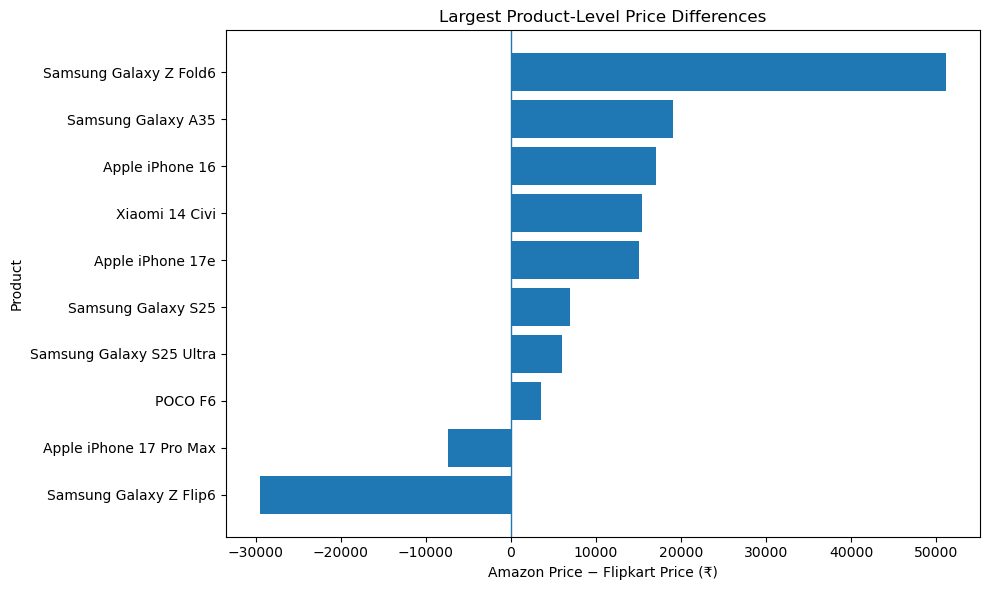

In [10]:
plot_df = top_price_gaps.head(10).sort_values(
    "price_difference"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["product_name"],
    plot_df["price_difference"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Amazon Price − Flipkart Price (₹)")
plt.ylabel("Product")
plt.title("Largest Product-Level Price Differences")

plt.tight_layout()
plt.show()

# Business Question 4: Which brands show the greatest pricing variation?

Compare brands based on cross-platform pricing differences.

Because brands contain different numbers of products, both the number of comparable products and the average absolute price gap are considered.

In [11]:
brand_analysis = (
    df.groupby("brand")
    .agg(
        products=("product_name", "count"),
        avg_amazon_price=("amazon_price", "mean"),
        avg_flipkart_price=("flipkart_price", "mean"),
        avg_price_difference=("price_difference", "mean"),
        avg_absolute_price_gap=("absolute_price_difference", "mean"),
        median_absolute_price_gap=("absolute_price_difference", "median"),
        avg_percentage_gap=("price_difference_pct", "mean")
    )
    .reset_index()
    .sort_values(
        "avg_absolute_price_gap",
        ascending=False
    )
)

brand_analysis

,brand,products,avg_amazon_price,avg_flipkart_price,avg_price_difference,avg_absolute_price_gap,median_absolute_price_gap,avg_percentage_gap
4,Samsung,7,70500.0,63107.571429,7392.428571,16324.428571,6901.0,22.740685
5,Xiaomi,1,44999.0,29598.000000,15401.000000,15401.000000,15401.0,41.291205
0,Apple,4,116047.5,109900.000000,6147.500000,9852.500000,11205.0,11.867620
2,POCO,1,33499.0,29999.000000,3500.000000,3500.000000,3500.0,11.023969
3,Redmi,1,29999.0,27795.000000,2204.000000,2204.000000,2204.0,7.627089
1,OnePlus,2,42683.5,41458.500000,1225.000000,1225.000000,1225.0,2.957991


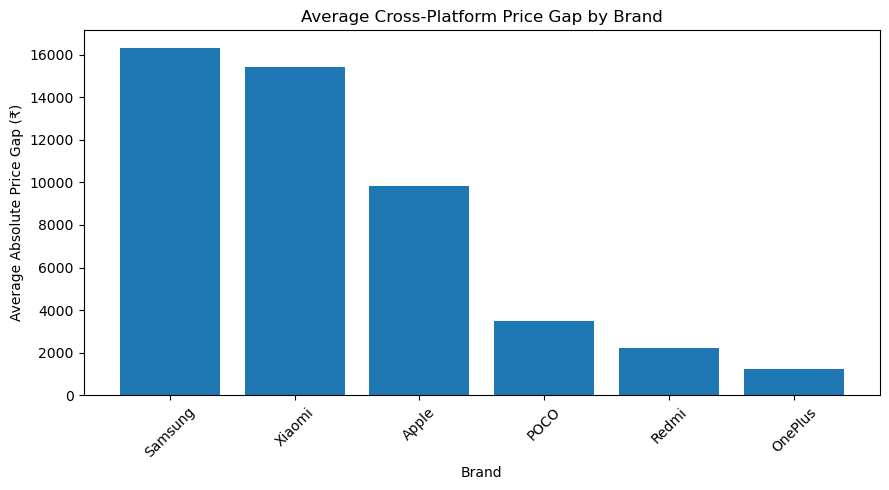

In [12]:
plt.figure(figsize=(9, 5))

plt.bar(
    brand_analysis["brand"],
    brand_analysis["avg_absolute_price_gap"]
)

plt.xlabel("Brand")
plt.ylabel("Average Absolute Price Gap (₹)")
plt.title("Average Cross-Platform Price Gap by Brand")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Business Question 5: Do higher discounts translate into greater price competitiveness?

Discount percentage alone does not determine whether a product is cheaper.

This analysis compares:

**MRP → Discount → Selling Price → Cross-Platform Price**

Only products with discount information available on both platforms are included.

In [13]:
# Convert discount columns to numeric and treat missing values as NaN
df["amazon_discount_pct"] = pd.to_numeric(
    df["amazon_discount_pct"], errors="coerce"
)

df["flipkart_discount_pct"] = pd.to_numeric(
    df["flipkart_discount_pct"], errors="coerce"
)

# Calculate each platform's average independently
discount_summary = pd.DataFrame({
    "Platform": ["Amazon", "Flipkart"],
    "Average Discount %": [
        df["amazon_discount_pct"].mean(),
        df["flipkart_discount_pct"].mean()
    ],
    "Valid Products": [
        df["amazon_discount_pct"].count(),
        df["flipkart_discount_pct"].count()
    ]
})

discount_summary["Average Discount %"] = (
    discount_summary["Average Discount %"].round(1)
)

display(discount_summary)

,Platform,Average Discount %,Valid Products
0,Amazon,13.8,13
1,Flipkart,24.5,12


In [14]:
# Compare discounts only where both platforms have valid data
discount_df = df.dropna(
    subset=["amazon_discount_pct", "flipkart_discount_pct"]
).copy()

discount_df["discount_difference"] = (
    discount_df["amazon_discount_pct"]
    - discount_df["flipkart_discount_pct"]
)

discount_df["higher_discount_platform"] = np.select(
    [
        discount_df["discount_difference"] > 0,
        discount_df["discount_difference"] < 0
    ],
    ["Amazon", "Flipkart"],
    default="Same"
)

display(
    discount_df[
        [
            "product_name",
            "amazon_discount_pct",
            "flipkart_discount_pct",
            "discount_difference",
            "higher_discount_platform",
            "amazon_price",
            "flipkart_price",
            "cheaper_platform"
        ]
    ].sort_values("discount_difference", ascending=False)
)

,product_name,amazon_discount_pct,flipkart_discount_pct,discount_difference,higher_discount_platform,amazon_price,flipkart_price,cheaper_platform
13,Samsung Galaxy Z Flip6,36.82,10.00,26.82,Amazon,69499,99000,Amazon
9,Samsung Galaxy A56,20.51,18.59,1.92,Amazon,38947,39890,Amazon
10,Samsung Galaxy M36,9.18,11.20,-2.02,Flipkart,23157,23975,Amazon
4,OnePlus Nord 6,10.62,12.87,-2.25,Flipkart,47368,46178,Flipkart
5,OnePlus Nord CE6,7.32,10.39,-3.07,Flipkart,37999,36739,Flipkart
12,Samsung Galaxy S25 Ultra,23.08,27.70,-4.62,Flipkart,99999,93990,Flipkart
7,Redmi Note 14 Pro+,14.29,20.58,-6.29,Flipkart,29999,27795,Flipkart
6,POCO F6,1.47,11.77,-10.30,Flipkart,33499,29999,Flipkart
11,Samsung Galaxy S25,27.18,47.62,-20.44,Flipkart,61900,54999,Flipkart
15,Xiaomi 14 Civi,18.18,46.18,-28.00,Flipkart,44999,29598,Flipkart


# Business Question 6: When one platform is cheaper, does it also have a lower customer rating?

The objective is to determine whether the platform offering the lower price also has a lower, similar, or higher customer rating.

This provides a more meaningful comparison than simply comparing average platform ratings.

In [15]:
df["rating_difference"] = (
    df["amazon_rating"] - df["flipkart_rating"]
)

def calculate_cheaper_rating_advantage(row):
    if row["cheaper_platform"] == "Amazon":
        return row["amazon_rating"] - row["flipkart_rating"]
    elif row["cheaper_platform"] == "Flipkart":
        return row["flipkart_rating"] - row["amazon_rating"]
    else:
        return 0

df["cheaper_platform_rating_advantage"] = df.apply(
    calculate_cheaper_rating_advantage,
    axis=1
)

def rating_relationship(value):
    if value > 0:
        return "Cheaper platform has higher rating"
    elif value < 0:
        return "Cheaper platform has lower rating"
    else:
        return "Same rating"

df["rating_relationship"] = df[
    "cheaper_platform_rating_advantage"
].apply(rating_relationship)

In [16]:
rating_relationship_summary = (
    df["rating_relationship"]
    .value_counts()
    .reset_index()
)

rating_relationship_summary.columns = [
    "Rating Relationship",
    "Product Count"
]

rating_relationship_summary

,Rating Relationship,Product Count
0,Cheaper platform has higher rating,8
1,Same rating,4
2,Cheaper platform has lower rating,4


In [17]:
rating_comparison = df[
    [
        "product_name",
        "amazon_price",
        "flipkart_price",
        "cheaper_platform",
        "amazon_rating",
        "flipkart_rating",
        "cheaper_platform_rating_advantage",
        "rating_relationship"
    ]
].sort_values(
    "cheaper_platform_rating_advantage",
    ascending=False
)

rating_comparison

,product_name,amazon_price,flipkart_price,cheaper_platform,amazon_rating,flipkart_rating,cheaper_platform_rating_advantage,rating_relationship
6,POCO F6,33499,29999,Flipkart,4.0,4.3,0.3,Cheaper platform has higher rating
5,OnePlus Nord CE6,37999,36739,Flipkart,4.3,4.5,0.2,Cheaper platform has higher rating
7,Redmi Note 14 Pro+,29999,27795,Flipkart,4.3,4.4,0.1,Cheaper platform has higher rating
0,Apple iPhone 16,86900,69900,Flipkart,4.5,4.6,0.1,Cheaper platform has higher rating
3,Apple iPhone 17e,79900,64900,Flipkart,4.4,4.5,0.1,Cheaper platform has higher rating
4,OnePlus Nord 6,47368,46178,Flipkart,4.4,4.5,0.1,Cheaper platform has higher rating
12,Samsung Galaxy S25 Ultra,99999,93990,Flipkart,4.5,4.6,0.1,Cheaper platform has higher rating
15,Xiaomi 14 Civi,44999,29598,Flipkart,4.2,4.3,0.1,Cheaper platform has higher rating
1,Apple iPhone 17 Pro,154900,154900,Same Price,4.5,4.7,0.0,Same rating
2,Apple iPhone 17 Pro Max,142490,149900,Amazon,4.7,4.7,0.0,Same rating


# Business Question 7: Which platform has stronger customer engagement based on review volume?

Review count is used as a proxy for customer engagement and product popularity.

Both average and median review counts are examined because review counts can be highly skewed by a small number of highly reviewed products.

In [18]:
review_summary = pd.DataFrame({
    "Platform": ["Amazon", "Flipkart"],
    "Average Reviews": [
        df["amazon_review_count"].mean(),
        df["flipkart_review_count"].mean()
    ],
    "Median Reviews": [
        df["amazon_review_count"].median(),
        df["flipkart_review_count"].median()
    ]
})

review_summary

,Platform,Average Reviews,Median Reviews
0,Amazon,1212.0625,654.5
1,Flipkart,20320.3125,2554.5


In [19]:
df["review_difference"] = (
    df["amazon_review_count"]
    - df["flipkart_review_count"]
)

review_comparison = df[
    [
        "product_name",
        "amazon_review_count",
        "flipkart_review_count",
        "review_difference"
    ]
].sort_values(
    "review_difference",
    ascending=False
)

review_comparison

,product_name,amazon_review_count,flipkart_review_count,review_difference
5,OnePlus Nord CE6,3256.0,1411,1845.0
14,Samsung Galaxy Z Fold6,381.0,268,113.0
13,Samsung Galaxy Z Flip6,167.0,225,-58.0
4,OnePlus Nord 6,2491.0,2624,-133.0
9,Samsung Galaxy A56,761.0,1091,-330.0
3,Apple iPhone 17e,172.0,525,-353.0
7,Redmi Note 14 Pro+,109.0,938,-829.0
15,Xiaomi 14 Civi,888.0,1876,-988.0
12,Samsung Galaxy S25 Ultra,2847.0,4272,-1425.0
2,Apple iPhone 17 Pro Max,663.0,2485,-1822.0


In [20]:
review_platform_summary = pd.DataFrame({
    "Platform": ["Amazon", "Flipkart"],
    "Products with Higher Review Count": [
        (df["amazon_review_count"] > df["flipkart_review_count"]).sum(),
        (df["flipkart_review_count"] > df["amazon_review_count"]).sum()
    ]
})

review_platform_summary

,Platform,Products with Higher Review Count
0,Amazon,2
1,Flipkart,14


# Business Question 8: Where are the biggest competitive pricing opportunities?

The objective is to identify products where the price difference between Amazon and Flipkart is substantial.

The analysis combines:

- Absolute price gap
- Percentage price gap
- Cheaper platform
- Customer rating
- Availability

A large price gap is considered a potential competitive opportunity, particularly when the cheaper platform also has a similar or higher customer rating.

In [21]:
competitive_opportunities = df[
    [
        "brand",
        "product_name",
        "ram_gb",
        "rom_gb",
        "amazon_price",
        "flipkart_price",
        "absolute_price_difference",
        "price_difference_pct",
        "cheaper_platform",
        "amazon_rating",
        "flipkart_rating",
        "cheaper_platform_rating_advantage",
        "rating_relationship",
        "amazon_availability",
        "flipkart_availability"
    ]
].copy()

competitive_opportunities = competitive_opportunities.sort_values(
    [
        "absolute_price_difference",
        "price_difference_pct"
    ],
    ascending=False
)

competitive_opportunities.head(10)

,brand,product_name,ram_gb,rom_gb,amazon_price,flipkart_price,absolute_price_difference,price_difference_pct,cheaper_platform,amazon_rating,flipkart_rating,cheaper_platform_rating_advantage,rating_relationship,amazon_availability,flipkart_availability
14,Samsung,Samsung Galaxy Z Fold6,12.0,256,159999,108900,51099,38.006092,Flipkart,4.3,4.2,-0.1,Cheaper platform has lower rating,In Stock,Unavailable
13,Samsung,Samsung Galaxy Z Flip6,12.0,256,69499,99000,29501,35.016232,Amazon,2.9,4.2,-1.3,Cheaper platform has lower rating,In Stock,In Stock
8,Samsung,Samsung Galaxy A35,8.0,256,39999,20999,19000,62.297124,Flipkart,4.4,4.4,0.0,Same rating,Unavailable,In Stock
0,Apple,Apple iPhone 16,NaN,128,86900,69900,17000,21.683673,Flipkart,4.5,4.6,0.1,Cheaper platform has higher rating,In Stock,In Stock
15,Xiaomi,Xiaomi 14 Civi,8.0,256,44999,29598,15401,41.291205,Flipkart,4.2,4.3,0.1,Cheaper platform has higher rating,Low Stock,Unavailable
3,Apple,Apple iPhone 17e,NaN,256,79900,64900,15000,20.718232,Flipkart,4.4,4.5,0.1,Cheaper platform has higher rating,In Stock,Unavailable
2,Apple,Apple iPhone 17 Pro Max,NaN,256,142490,149900,7410,5.068573,Amazon,4.7,4.7,0.0,Same rating,In Stock,In Stock
11,Samsung,Samsung Galaxy S25,12.0,128,61900,54999,6901,11.806773,Flipkart,4.8,4.6,-0.2,Cheaper platform has lower rating,In Stock,Unavailable
12,Samsung,Samsung Galaxy S25 Ultra,12.0,256,99999,93990,6009,6.195197,Flipkart,4.5,4.6,0.1,Cheaper platform has higher rating,In Stock,In Stock
6,POCO,POCO F6,8.0,256,33499,29999,3500,11.023969,Flipkart,4.0,4.3,0.3,Cheaper platform has higher rating,Low Stock,Unavailable


In [22]:
top_opportunities = competitive_opportunities.head(10).copy()

top_opportunities

,brand,product_name,ram_gb,rom_gb,amazon_price,flipkart_price,absolute_price_difference,price_difference_pct,cheaper_platform,amazon_rating,flipkart_rating,cheaper_platform_rating_advantage,rating_relationship,amazon_availability,flipkart_availability
14,Samsung,Samsung Galaxy Z Fold6,12.0,256,159999,108900,51099,38.006092,Flipkart,4.3,4.2,-0.1,Cheaper platform has lower rating,In Stock,Unavailable
13,Samsung,Samsung Galaxy Z Flip6,12.0,256,69499,99000,29501,35.016232,Amazon,2.9,4.2,-1.3,Cheaper platform has lower rating,In Stock,In Stock
8,Samsung,Samsung Galaxy A35,8.0,256,39999,20999,19000,62.297124,Flipkart,4.4,4.4,0.0,Same rating,Unavailable,In Stock
0,Apple,Apple iPhone 16,NaN,128,86900,69900,17000,21.683673,Flipkart,4.5,4.6,0.1,Cheaper platform has higher rating,In Stock,In Stock
15,Xiaomi,Xiaomi 14 Civi,8.0,256,44999,29598,15401,41.291205,Flipkart,4.2,4.3,0.1,Cheaper platform has higher rating,Low Stock,Unavailable
3,Apple,Apple iPhone 17e,NaN,256,79900,64900,15000,20.718232,Flipkart,4.4,4.5,0.1,Cheaper platform has higher rating,In Stock,Unavailable
2,Apple,Apple iPhone 17 Pro Max,NaN,256,142490,149900,7410,5.068573,Amazon,4.7,4.7,0.0,Same rating,In Stock,In Stock
11,Samsung,Samsung Galaxy S25,12.0,128,61900,54999,6901,11.806773,Flipkart,4.8,4.6,-0.2,Cheaper platform has lower rating,In Stock,Unavailable
12,Samsung,Samsung Galaxy S25 Ultra,12.0,256,99999,93990,6009,6.195197,Flipkart,4.5,4.6,0.1,Cheaper platform has higher rating,In Stock,In Stock
6,POCO,POCO F6,8.0,256,33499,29999,3500,11.023969,Flipkart,4.0,4.3,0.3,Cheaper platform has higher rating,Low Stock,Unavailable


In [23]:
opportunity_view = top_opportunities[
    [
        "brand",
        "product_name",
        "absolute_price_difference",
        "price_difference_pct",
        "cheaper_platform",
        "rating_relationship",
        "amazon_availability",
        "flipkart_availability"
    ]
]

opportunity_view

,brand,product_name,absolute_price_difference,price_difference_pct,cheaper_platform,rating_relationship,amazon_availability,flipkart_availability
14,Samsung,Samsung Galaxy Z Fold6,51099,38.006092,Flipkart,Cheaper platform has lower rating,In Stock,Unavailable
13,Samsung,Samsung Galaxy Z Flip6,29501,35.016232,Amazon,Cheaper platform has lower rating,In Stock,In Stock
8,Samsung,Samsung Galaxy A35,19000,62.297124,Flipkart,Same rating,Unavailable,In Stock
0,Apple,Apple iPhone 16,17000,21.683673,Flipkart,Cheaper platform has higher rating,In Stock,In Stock
15,Xiaomi,Xiaomi 14 Civi,15401,41.291205,Flipkart,Cheaper platform has higher rating,Low Stock,Unavailable
3,Apple,Apple iPhone 17e,15000,20.718232,Flipkart,Cheaper platform has higher rating,In Stock,Unavailable
2,Apple,Apple iPhone 17 Pro Max,7410,5.068573,Amazon,Same rating,In Stock,In Stock
11,Samsung,Samsung Galaxy S25,6901,11.806773,Flipkart,Cheaper platform has lower rating,In Stock,Unavailable
12,Samsung,Samsung Galaxy S25 Ultra,6009,6.195197,Flipkart,Cheaper platform has higher rating,In Stock,In Stock
6,POCO,POCO F6,3500,11.023969,Flipkart,Cheaper platform has higher rating,Low Stock,Unavailable


## Save the EDA Dataset

The final EDA dataset contains the matched product-level comparison along with derived analytical metrics used throughout the analysis.

In [24]:
df.to_csv(
    "../data/processed/final_mobile_price_comparison_eda.csv",
    index=False
)

print("EDA dataset saved successfully.")
print("Rows:", len(df))
print("Columns:", len(df.columns))

EDA dataset saved successfully.
Rows: 16
Columns: 30


# Final EDA Conclusion

## 1. Project Overview

This project analysed mobile phone pricing and customer-related metrics across Amazon and Flipkart to understand platform competitiveness and identify potential pricing opportunities.

The analysis used web-scraped product data collected on **7 October 2026**. After data validation, cleaning, product standardisation, and exact product-variant matching, **16 comparable mobile product variants** were analysed.

The key metrics included current price, MRP, discount percentage, customer rating, review count, product availability, and the price difference between platforms.

## 2. Key Findings

### Finding 1: Flipkart was cheaper for most comparable products

- Flipkart offered lower prices for **11 out of 16 products**.
- Amazon offered lower prices for **4 products**.
- Both platforms offered the same price for **1 product**.

This indicates that Flipkart was more price-competitive across the matched products in this particular sample. However, the result should not be generalised to every mobile phone or to the entire marketplaces.

### Finding 2: Significant price differences existed for several products

The comparison revealed substantial price gaps for some products.

Examples from the analysis included:

- **Samsung Galaxy Z Fold6:** Flipkart was cheaper by ₹51,099.
- **Samsung Galaxy Z Flip6:** Amazon was cheaper by ₹29,501.
- **Samsung Galaxy A35:** Flipkart was cheaper by ₹19,000.
- **Apple iPhone 16:** Flipkart was cheaper by ₹17,000.
- **Xiaomi 14 Civi:** Flipkart was cheaper by ₹15,401.
- **Apple iPhone 17e:** Flipkart was cheaper by ₹15,000.

These results demonstrate why comparing the same product across platforms is important. The more competitive platform varied by product, so neither marketplace was consistently cheaper for every device.

### Finding 3: The cheaper platform did not always have the higher customer rating

The rating comparison showed that price competitiveness and customer ratings did not always move together.

- Some products were cheaper on a platform that also had a higher rating.
- For other products, the cheaper platform had a lower rating.
- Some products had identical ratings across both platforms.

Therefore, customers and retailers should consider both price and customer ratings rather than relying on price alone. Ratings are useful indicators of customer feedback, but they do not independently establish product quality or seller reliability.

### Finding 4: Flipkart had higher review counts for most matched products

Among the 16 matched products:

- Flipkart had a higher review count for **14 products**.
- Amazon had a higher review count for **2 products**.

This indicates that Flipkart listings in this sample generally displayed larger review volumes. However, review counts may reflect differences in listing history, customer reach, and review aggregation practices. A higher count does not necessarily mean a product is better or that the platform has more sales.

### Finding 5: Product availability differed between platforms

The availability comparison identified products that were listed as in stock, in low stock, or unavailable.

Some products were available on one platform but unavailable on the other. This matters because the lowest listed price is not necessarily a practical buying option when the product is unavailable.

For a reliable competitive assessment, pricing should therefore be evaluated alongside availability. Availability should also be treated as a snapshot because marketplace stock status can change quickly.

### Finding 6: Discount comparisons depend on reliable MRP data

Discount percentages were recalculated using current price and MRP:

Discount % = (MRP-Current Price) * 100 / MRP


This approach provides a consistent calculation across both platforms. However, MRP and discount information were missing for some listings. Those records should not be interpreted as having zero discount.

Consequently, discount-related conclusions should be based only on products with valid MRP and current-price values. A larger displayed discount also does not necessarily mean a lower final selling price.

### Finding 7: Exact product-variant matching was essential

The analysis matched products using standardised product names and storage configurations, including RAM where available.

Six initially considered product pairs had different RAM or storage configurations and were excluded from the exact comparison. For example, two listings for the same model may have different storage capacities or RAM configurations, making their prices unsuitable for a direct comparison.

This step improved analytical reliability by ensuring that the price differences reflected comparable configurations rather than differences in product specifications.

### Finding 8: The largest price gaps represent potential competitive opportunities

Products with substantial price gaps can help a retailer identify where its prices may be less competitive or where further investigation could be valuable.

The analysis highlighted both Amazon and Flipkart opportunities. For example, Flipkart had a large price advantage for the Samsung Galaxy Z Fold6, while Amazon had a substantial price advantage for the Samsung Galaxy Z Flip6.

These findings can guide further investigation into competitor pricing, promotional activity, stock availability, and product positioning. A price gap alone does not establish the reason for the difference or guarantee that matching a competitor's price would be profitable.

## 3. Business Recommendations

Based on the findings, the following actions are recommended:

1. **Monitor competitor prices:** Track comparable mobile models regularly to identify meaningful price changes and emerging competitive gaps.
2. **Prioritise high-gap products:** Investigate products with large absolute or percentage price differences, especially high-value devices.
3. **Use product-level pricing strategies:** Avoid assuming that one platform is always cheaper. Review pricing decisions separately for each model and configuration.
4. **Consider customer feedback alongside price:** Evaluate ratings and review volumes together with price before making product-positioning decisions.
5. **Include availability in comparisons:** Distinguish between products that are available to purchase and listings that are temporarily unavailable.
6. **Validate discount claims:** Use only reliable MRP data when comparing discounts, and avoid treating missing values as zero.
7. **Automate repeat data collection:** Collect comparable product data at regular intervals to monitor price movements and distinguish temporary changes from persistent pricing differences.

## 4. Limitations of the Analysis

- The analysis covered a limited sample of **16 exact product matches**, not the entire mobile phone catalogue on either marketplace.
- Data was collected on **7 October 2026**, so prices, discounts, ratings, review counts, and availability may have changed since collection.
- Some listings had missing MRP, discount, or review-count information.
- The comparison reflects publicly displayed listing information at the time of scraping; it does not verify final checkout prices, seller-specific conditions, delivery charges, or promotional eligibility.
- The findings establish observed associations and price differences, not the causes of those differences or their effect on sales and profitability.

## 5. Final Business Conclusion

The analysis found that **Flipkart offered lower prices for 11 of the 16 comparable mobile products**, while Amazon was cheaper for four and one had the same price on both platforms. However, substantial product-level differences showed that competitiveness varied by model.

The findings also demonstrated that price should not be evaluated in isolation. Customer ratings, review volumes, product availability, and the reliability of MRP information all contribute to a more useful comparison.

From a business perspective, the most valuable outcome is a repeatable method for comparing identical product variants across marketplaces, identifying significant pricing gaps, and prioritising products for further investigation.

This project demonstrates how web scraping, Python-based data validation and cleaning, product matching, exploratory data analysis, and business-focused metrics can transform raw marketplace listings into actionable competitive intelligence.

**Overall conclusion:** Flipkart was more price-competitive across this sample, but the best pricing decision depends on the individual product, its comparable configuration, customer feedback, and current availability.